In [ ]:
# Code to validate the results of stochastic rasters
# V1 - 2026-09-10 - JPK - design time series
# refer Zhang 2022 for validation scheme details


## A. Prediction intervals
# Use test station observations
# Calculate hits and misses at 50% confidence [0.25, 0.75] range; and 90% confidence range [0.05, 0.95] for the entire period
# Visualize for one randomly picked 6-month period for one tmax and tmin station

## B. reliability diagram
# for tmax --> 0.8 and 0.95 threshold observations
# for tmin --> 0.2 and 0.05 threshold observations


## C. Brier Scores

In [ ]:
# A. PI
# first match the pixel to test station coordinates and get the cluster - store a df
# daily loop - sample raster values [in array of 100 predictions] from each station location per day - get a df
# rearrange each point prediction in ascending and extract the 5th, 25th, 75th and 95th value
# merge the day's actual observed value to the point observation df
# calculate hits or misses


# libraries
import os
import numpy as np  
import pandas as pd 
import matplotlib.pyplot as plt
import pyarrow
import xarray as xr 
import rioxarray as rxr
import rasterio
from tqdm import tqdm

# paths and files
tmax_pq = pd.read_parquet(r"F:\ClimateDataWS\Data\Insitu\Cleaned\tmax_cleaned.parquet")
tmin_pq = pd.read_parquet(r"F:\ClimateDataWS\Data\Insitu\Cleaned\tmin_cleaned.parquet")
tmax_test_stn = pd.read_csv(r"F:\ClimateDataWS\Data\Processed\Split_stations\tmax_test_stations.csv")
tmin_test_stn = pd.read_csv(r"F:\ClimateDataWS\Data\Processed\Split_stations\tmin_test_stations.csv")

In [9]:
# sample quantile files from stochastic rasters

tmax_stn_points = list(zip(tmax_test_stn['long'], tmax_test_stn['lat']))
tmin_stn_points = list(zip(tmin_test_stn['long'], tmin_test_stn['lat']))

start_year, start_month, start_day = 2001, 1, 1
end_year, end_month, end_day = 2025, 12, 31


daily_range = pd.period_range(
    start = f"{start_year}-{start_month:02d}-{start_day:02d}",
    end = f"{end_year}-{end_month:02d}-{end_day:02d}",
    freq= "D"
)

for t_var in ["tmax", "tmin"]:
    results = []
    stn_points = tmax_stn_points if t_var == "tmax" else tmin_stn_points
    test_stn   = tmax_test_stn   if t_var == "tmax" else tmin_test_stn
    for period in tqdm(daily_range, desc = f"Daily feature extraction for {t_var}"):
        file_path = fr"F:\ClimateDataWS\Data\Processed\Daily_bias_correction\QRF_products\{t_var[:1].upper() + t_var[1:]}\Stochastic\{t_var}_QRFSt_{period.year}{period.month:02d}{period.day:02d}.tif"
        with rasterio.open(file_path) as src:
            crs = src.crs
            if crs == "EPSG:4326":
                sampled_values = list(src.sample(stn_points))                
                for i, value in enumerate(sampled_values):
                    results.append({
                    'date': f'{period.year}-{period.month}-{period.day}',
                    'index_no': test_stn.iloc[i]['index_no'],
                    'cluster':  test_stn.iloc[i]['cluster_id'],
                    'q5': (np.sort(value))[4],
                    'q25': (np.sort(value))[24],
                    'q50': (np.sort(value))[49],
                    'q75': (np.sort(value))[74],
                    'q95': (np.sort(value))[94],
                    'value_array':(np.sort(value))
                })
    if t_var == "tmax":
        tmax_sampled_df = pd.DataFrame(results)
        tmax_sampled_df['date'] = pd.to_datetime(tmax_sampled_df['date']).copy()
        test_ids_tmax = set(tmax_test_stn["index_no"])
        tmax_test = tmax_pq[tmax_pq["index_no"].isin(test_ids_tmax)].copy()
        tmax_comparision_df = tmax_sampled_df.merge(tmax_test, on = ['date', 'index_no'], how = 'inner').drop(columns=['year', 'month', 'day'])
        tmax_comparision_df = tmax_comparision_df.rename(columns={'max_temp': 'observation'})
        tmax_comparision_df = tmax_comparision_df[['date', 'index_no', 'cluster', 'lat', 'long', 'elevation', 'q5', 'q25', 'q50', 'q75', 'q95', 'observation', 'value_array']]
    if t_var == "tmin":
        tmin_sampled_df = pd.DataFrame(results)
        tmin_sampled_df['date'] = pd.to_datetime(tmin_sampled_df['date']).copy()
        test_ids_tmin = set(tmin_test_stn["index_no"])
        tmin_test = tmin_pq[tmin_pq["index_no"].isin(test_ids_tmin)].copy()
        tmin_comparision_df = tmin_sampled_df.merge(tmin_test, on = ['date', 'index_no'], how = 'inner').drop(columns=['year', 'month', 'day'])
        tmin_comparision_df = tmin_comparision_df.rename(columns={'min_temp': 'observation'})
        tmin_comparision_df = tmin_comparision_df[['date', 'index_no', 'cluster', 'lat', 'long', 'elevation', 'q5', 'q25', 'q50', 'q75', 'q95', 'observation', 'value_array']]


Daily feature extraction for tmin: 100%|██████████| 9131/9131 [15:55<00:00,  9.55it/s]


In [10]:
tmax_comparision_df['Hit_50'] = np.where(((tmax_comparision_df['observation']>= tmax_comparision_df['q25']) & (tmax_comparision_df['observation']<= tmax_comparision_df['q75'])), 1, 0)
tmax_comparision_df['Hit_90'] = np.where(((tmax_comparision_df['observation']>= tmax_comparision_df['q5']) & (tmax_comparision_df['observation']<= tmax_comparision_df['q95'])), 1, 0)

# Print overall hit rates
print(f"Overall 50th confidence hit rate for tmax: {tmax_comparision_df['Hit_50'].mean():.4f}")
print(f"Overall 90th confidence hit rate for tmax: {tmax_comparision_df['Hit_90'].mean():.4f}")

# Stratify by cluster
tmax_hit_rates_df = tmax_comparision_df.groupby('cluster')[['Hit_50', 'Hit_90']].mean().reset_index()

# Rename columns for better readability
tmax_hit_rates_df = tmax_hit_rates_df.rename(columns={
    'Hit_50': 'Hit_Rate_50_CI',
    'Hit_90': 'Hit_Rate_90_CI'
})
tmax_hit_rates_df.loc[len(tmax_hit_rates_df)] = ["Overall", tmax_comparision_df['Hit_50'].mean(), tmax_comparision_df['Hit_90'].mean()]

output_dir = r"F:\ClimateDataWS\Data\Processed\Daily_bias_correction\Validation_results"
# Display the resulting dataframe
tmax_hit_rates_df.to_csv(os.path.join(output_dir, "Tmax_hit_rates.csv"), index = False)

Overall 50th confidence hit rate for tmax: 0.5610
Overall 90th confidence hit rate for tmax: 0.9148


In [11]:
tmin_comparision_df['Hit_50'] = np.where(((tmin_comparision_df['observation']>= tmin_comparision_df['q25']) & (tmin_comparision_df['observation']<= tmin_comparision_df['q75'])),
                     1, 0)
tmin_comparision_df['Hit_90'] = np.where(((tmin_comparision_df['observation']>= tmin_comparision_df['q5']) & (tmin_comparision_df['observation']<= tmin_comparision_df['q95'])),
                     1, 0)
print(f"Overall 50th confidence hit rate for tmin:{tmin_comparision_df['Hit_50'].mean()}")
print(f"Overall 90th confidence hit rate for tmin:{tmin_comparision_df['Hit_90'].mean()}")

# Stratify by cluster
tmin_hit_rates_df = tmin_comparision_df.groupby('cluster')[['Hit_50', 'Hit_90']].mean().reset_index()

# Rename columns for better readability
tmin_hit_rates_df = tmin_hit_rates_df.rename(columns={
    'Hit_50': 'Hit_Rate_50_CI',
    'Hit_90': 'Hit_Rate_90_CI'
})


# Display the resulting dataframe
tmin_hit_rates_df.loc[len(tmin_hit_rates_df)] = ["Overall", tmin_comparision_df['Hit_50'].mean(), tmin_comparision_df['Hit_90'].mean()]
tmin_hit_rates_df.to_csv(os.path.join(output_dir, "Tmin_hit_rates.csv"), index = False)

Overall 50th confidence hit rate for tmin:0.5593752098784384
Overall 90th confidence hit rate for tmin:0.9028946434225297


In [12]:
## B. reliability diagram
# find threshold observation value in temperature units
# convert the true observations to binary o(station, time)
# compute ensemble predicted probabilities f(s, t)
# bin and calculate coordinates

# filter dfs
tmax_rd_df = tmax_comparision_df[['date', 'index_no', 'observation', 'value_array']]
tmin_rd_df = tmin_comparision_df[['date', 'index_no', 'observation', 'value_array']]

# find threshold observations
tmax_threshold_80 = np.percentile(tmax_rd_df['observation'].to_numpy(), 80)
tmax_threshold_95 = np.percentile(tmax_rd_df['observation'].to_numpy(), 95)
tmin_threshold_20 = np.percentile(tmin_rd_df['observation'].to_numpy(), 20)
tmin_threshold_5 = np.percentile(tmin_rd_df['observation'].to_numpy(), 5)

# ==========================================
# TMAX 95 (Greater than threshold)
# ==========================================
tmax_80_df = tmax_rd_df.copy()
tmax_80_df['binary_observation'] = np.where(tmax_80_df['observation'] > tmax_threshold_80, 1, 0)
tmax_80_df['ensemble_probability'] = tmax_80_df['value_array'].apply(
    lambda ensembles: np.count_nonzero(np.array(ensembles) > tmax_threshold_80) / len(ensembles)
)
tmax_80_df = tmax_80_df[['binary_observation', 'ensemble_probability']].reset_index(drop=True)

bin_edges = [i/100 for i in range(0, 110, 10)]
bin_labels = [f"{i}-{i+10}" for i in range(0, 100, 10)]
tmax_80_df['bin'] = pd.cut(tmax_80_df['ensemble_probability'], bins = bin_edges, labels = bin_labels, include_lowest=True)

tmax_80_rd = (tmax_80_df).groupby(tmax_80_df['bin'], observed = False).agg(
    observation_freq = ('binary_observation', 'mean'),
    predicted_prob = ('ensemble_probability', 'mean')
).reset_index()

# ==========================================
# TMAX 95 (Greater than threshold)
# ==========================================
tmax_95_df = tmax_rd_df.copy()
tmax_95_df['binary_observation'] = np.where(tmax_95_df['observation'] > tmax_threshold_95, 1, 0)
tmax_95_df['ensemble_probability'] = tmax_95_df['value_array'].apply(
    lambda ensembles: np.count_nonzero(np.array(ensembles) > tmax_threshold_95) / len(ensembles)
)
tmax_95_df = tmax_95_df[['binary_observation', 'ensemble_probability']].reset_index(drop=True)
tmax_95_df['bin'] = pd.cut(tmax_95_df['ensemble_probability'], bins=bin_edges, labels=bin_labels, include_lowest=True)

tmax_95_rd = tmax_95_df.groupby(tmax_95_df['bin'], observed=False).agg(
    observation_freq=('binary_observation', 'mean'),
    predicted_prob=('ensemble_probability', 'mean')
).reset_index()


# ==========================================
# TMIN 20 (Less than threshold)
# ==========================================
tmin_20_df = tmin_rd_df.copy()
tmin_20_df['binary_observation'] = np.where(tmin_20_df['observation'] < tmin_threshold_20, 1, 0)
tmin_20_df['ensemble_probability'] = tmin_20_df['value_array'].apply(
    lambda ensembles: np.count_nonzero(np.array(ensembles) < tmin_threshold_20) / len(ensembles)
)
tmin_20_df = tmin_20_df[['binary_observation', 'ensemble_probability']].reset_index(drop=True)
tmin_20_df['bin'] = pd.cut(tmin_20_df['ensemble_probability'], bins=bin_edges, labels=bin_labels, include_lowest=True)

tmin_20_rd = tmin_20_df.groupby(tmin_20_df['bin'], observed=False).agg(
    observation_freq=('binary_observation', 'mean'),
    predicted_prob=('ensemble_probability', 'mean')
).reset_index()


# ==========================================
# TMIN 5 (Less than threshold)
# ==========================================
tmin_5_df = tmin_rd_df.copy()
tmin_5_df['binary_observation'] = np.where(tmin_5_df['observation'] < tmin_threshold_5, 1, 0)
tmin_5_df['ensemble_probability'] = tmin_5_df['value_array'].apply(
    lambda ensembles: np.count_nonzero(np.array(ensembles) < tmin_threshold_5) / len(ensembles)
)
tmin_5_df = tmin_5_df[['binary_observation', 'ensemble_probability']].reset_index(drop=True)
tmin_5_df['bin'] = pd.cut(tmin_5_df['ensemble_probability'], bins=bin_edges, labels=bin_labels, include_lowest=True)

tmin_5_rd = tmin_5_df.groupby(tmin_5_df['bin'], observed=False).agg(
    observation_freq=('binary_observation', 'mean'),
    predicted_prob=('ensemble_probability', 'mean')
).reset_index()

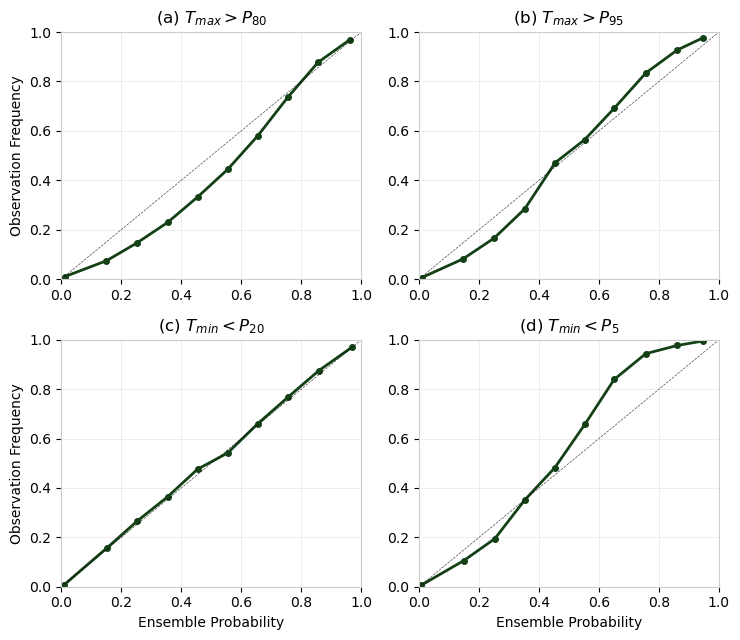

In [13]:
# RD visualization
fig, ax = plt.subplots(nrows=2, ncols=2, figsize=(7.5, 6.5))

ax[0, 0].plot(tmax_80_rd['predicted_prob'], tmax_80_rd['observation_freq'], color = '#144016', lw = 2, marker='o', markersize= 4)
ax[0, 0].axline((0, 0), slope=1, color='black', linestyle='--', alpha = 0.7, lw =0.5)
ax[0, 0].set_title(r"(a) $T_{max} > P_{80}$")
ax[0, 0].set_ylabel("Observation Frequency")

ax[0, 1].plot(tmax_95_rd['predicted_prob'], tmax_95_rd['observation_freq'], color = '#144016', lw = 2, marker='o', markersize= 4)
ax[0, 1].axline((0, 0), slope=1, color='black', linestyle='--', alpha = 0.7, lw =0.5)
ax[0, 1].set_title(r"(b) $T_{max} > P_{95}$")

ax[1, 0].plot(tmin_20_rd['predicted_prob'], tmin_20_rd['observation_freq'], color = '#144016', lw = 2, marker='o', markersize= 4)
ax[1, 0].axline((0, 0), slope=1, color='black', linestyle='--', alpha = 0.7, lw =0.5)
ax[1, 0].set_title(r"(c) $T_{min} < P_{20}$")
ax[1, 0].set_ylabel("Observation Frequency")
ax[1, 0].set_xlabel("Ensemble Probability")

ax[1, 1].plot(tmin_5_rd['predicted_prob'], tmin_5_rd['observation_freq'], color = '#144016', lw = 2, marker='o', markersize= 4)
ax[1, 1].axline((0, 0), slope=1, color='black', linestyle='--', alpha = 0.7, lw =0.5)
ax[1, 1].set_title("(d) $T_{min} < P_{5}$")
ax[1, 1].set_xlabel("Ensemble Probability")

for row in ax:
    for a in row:
        a.set_xlim(0, 1)
        a.set_ylim(0, 1)

        a.grid(True, which='both', color='#E6E6E6', linestyle='-', linewidth=0.5, zorder=0)
        
        # Optional: Lighten the outer bounding box (spines) for an even cleaner look
        for spine in a.spines.values():
            spine.set_color('#CCCCCC')
            spine.set_linewidth(0.8)

plt.tight_layout()
plt.savefig(os.path.join(output_dir, "Reliability_diagram_temp.tiff"), dpi = 300)
plt.show()


In [14]:
# C Brier Scores

def brier_decomposition(df, obs_col='binary_observation', prob_col='ensemble_probability', bin_col='bin'):
    n_total = len(df)
    obar = df[obs_col].mean()

    grouped = df.groupby(bin_col, observed=False).agg(
        n_k=(obs_col, 'count'),
        obar_k=(obs_col, 'mean'),
        fbar_k=(prob_col, 'mean')
    ).reset_index()
    grouped = grouped[grouped['n_k'] > 0]  # drop empty bins, else obar_k is NaN

    reliability = (grouped['n_k'] * (grouped['fbar_k'] - grouped['obar_k'])**2).sum() / n_total
    resolution  = (grouped['n_k'] * (grouped['obar_k'] - obar)**2).sum() / n_total
    uncertainty = obar * (1 - obar)

    brier_score = reliability - resolution + uncertainty
    brier_score_direct = ((df[prob_col] - df[obs_col])**2).mean()  # sanity check, ~equal to above

    bss = 1 - brier_score / uncertainty if uncertainty > 0 else np.nan

    return {
        'brier_score': brier_score,
        'brier_score_check': brier_score_direct,
        'reliability': reliability,
        'resolution': resolution,
        'uncertainty': uncertainty,
        'brier_skill_score': bss,
        'base_rate': obar,
        'n_obs': n_total
    }

bs_results = {
    'tmax_80': brier_decomposition(tmax_80_df),
    'tmax_95': brier_decomposition(tmax_95_df),
    'tmin_20': brier_decomposition(tmin_20_df),
    'tmin_5':  brier_decomposition(tmin_5_df),
}

bs_summary = pd.DataFrame(bs_results).T
print(bs_summary)
bs_summary.to_csv(os.path.join(output_dir, "Brier_score.csv"), index=False)

         brier_score  brier_score_check  reliability  resolution  uncertainty  \
tmax_80     0.059487           0.059193     0.002423    0.098229     0.155294   
tmax_95     0.019663           0.019592     0.000439    0.025137     0.044362   
tmin_20     0.051950           0.051525     0.000040    0.107002     0.158912   
tmin_5      0.017636           0.017488     0.000565    0.027471     0.044542   

         brier_skill_score  base_rate     n_obs  
tmax_80           0.616936   0.192256  106176.0  
tmax_95           0.556751   0.046527  106176.0  
tmin_20           0.673092   0.198192  104227.0  
tmin_5            0.604052   0.046725  104227.0  


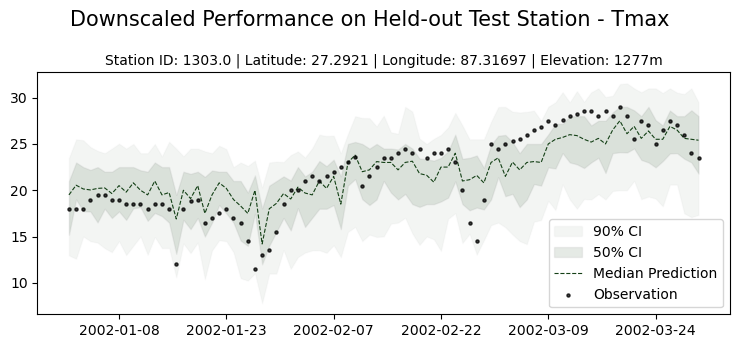

In [15]:
import random
import seaborn as sns
import matplotlib.ticker as ticker
random.seed(6)
random_number_idx = random.randint(0, len(tmax_comparision_df['index_no'].unique())-1)
#pick a random station
picked_idx = (tmax_comparision_df['index_no'].unique())[random_number_idx]

vis_tmax = tmax_comparision_df[(tmax_comparision_df['index_no'] == picked_idx) & (tmax_comparision_df['date'] >= '2002-01-01') & (tmax_comparision_df['date'] <= '2002-03-30') ]

fig, ax = plt.subplots(figsize=(7.5, 3.5))

ax.fill_between(vis_tmax['date'], vis_tmax['q5'], vis_tmax['q95'], 
                color='#144016', alpha=0.05, edgecolor='darkgray', 
                linewidth=1, label='90% CI')
ax.fill_between(vis_tmax['date'], vis_tmax['q25'], vis_tmax['q75'], 
                color='#144016', alpha=0.11, edgecolor='gray', 
                linewidth=1, label='50% CI')
ax.plot(vis_tmax['date'], vis_tmax['q50'], color='#144016', linestyle='--', linewidth=0.8, label = 'Median Prediction')
ax.scatter(vis_tmax['date'], vis_tmax['observation'], s=5, c='black', alpha=0.75, zorder=3, label='Observation')
ax.legend()
ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=8))
plt.suptitle("Downscaled Performance on Held-out Test Station - Tmax", fontsize = 15)
plt.title(f"Station ID: {picked_idx} | Latitude: {vis_tmax['lat'].iloc[0]} | Longitude: {vis_tmax['long'].iloc[0]} | Elevation: {vis_tmax['elevation'].iloc[0]}m", fontsize =10)
plt.tight_layout()
plt.savefig(os.path.join(output_dir, "Stochastic_PI_Tmax.png"), dpi = 300)
plt.show()

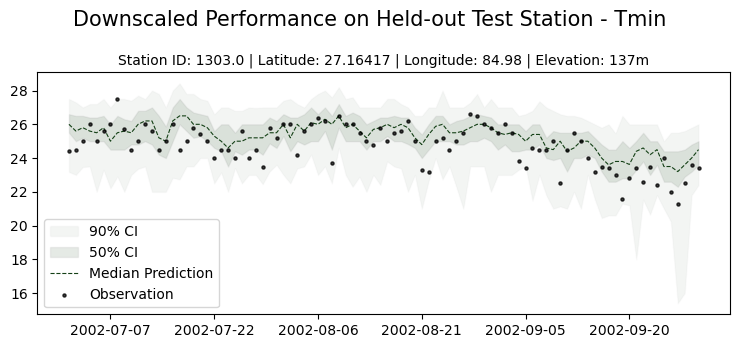

In [16]:
random.seed(21)
random_number_idx = random.randint(0, len(tmin_comparision_df['index_no'].unique())-1)
#pick a random station
picked_idx_tmin = (tmin_comparision_df['index_no'].unique())[random_number_idx]

vis_tmin = tmin_comparision_df[
    (tmin_comparision_df['index_no'] == picked_idx_tmin) &
    (tmin_comparision_df['date'] >= '2002-07-01') &
    (tmin_comparision_df['date'] <= '2002-09-30')
]

fig, ax = plt.subplots(figsize=(7.5, 3.5))

# 90 % confidence interval
ax.fill_between(
    vis_tmin['date'], vis_tmin['q5'], vis_tmin['q95'],
    color='#144016', alpha=0.05, edgecolor='darkgray',
    linewidth=1, label='90% CI'
)

# 50 % confidence interval
ax.fill_between(
    vis_tmin['date'], vis_tmin['q25'], vis_tmin['q75'],
    color='#144016', alpha=0.11, edgecolor='gray',
    linewidth=1, label='50% CI'
)

# Median prediction line
ax.plot(
    vis_tmin['date'], vis_tmin['q50'],
    color='#144016', linestyle='--', linewidth=0.8,
    label='Median Prediction'
)

# Observation points
ax.scatter(
    vis_tmin['date'], vis_tmin['observation'],
    s=5, c='black', alpha=0.75, zorder=3,
    label='Observation'
)

ax.legend()
ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=8))

plt.suptitle("Downscaled Performance on Held-out Test Station - Tmin", fontsize=15)
plt.title(
    f"Station ID: {picked_idx} | Latitude: {vis_tmin['lat'].iloc[0]} | "
    f"Longitude: {vis_tmin['long'].iloc[0]} | Elevation: {vis_tmin['elevation'].iloc[0]}m",
    fontsize=10
)

plt.tight_layout()
plt.savefig(os.path.join(output_dir, "Stochastic_PI_Tmin.png"), dpi = 300)    
plt.show()
